In [0]:
import sys, os, subprocess, tempfile, importlib.metadata as md

fijas, faltan = [], []
for paquete in ("numpy", "pandas", "pillow", "matplotlib", "scipy", "pyarrow"):
    try:
        fijas.append(f"{paquete}=={md.version(paquete)}")
    except md.PackageNotFoundError:
        if paquete != "pyarrow":
            faltan.append(paquete)          # en Jupyter local puede faltar alguno

restricciones = os.path.join(tempfile.gettempdir(), "restricciones_pip.txt")
with open(restricciones, "w") as f:
    # OpenCV 4.11.0.86 fijo: 4.14 y 5.x abortan al importarse en Databricks ("FATAL FIPS SELFTEST FAILURE").
    # rapidocr lo trae como dependencia.
    f.write("\n".join(fijas + ["opencv-python==4.11.0.86", "opencv-python-headless==4.11.0.86"]))

nuevas = ["pillow-heif", "openpyxl", "rapidocr_onnxruntime", "opencv-python-headless==4.11.0.86"] + faltan
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-c", restricciones, *nuevas])
print("Versiones fijas:", ", ".join(fijas))
print("Instalado:", ", ".join(f"{p}=={md.version(p)}" for p in ["pillow-heif", "openpyxl", "rapidocr_onnxruntime"]))

Versiones fijas: numpy==2.3.4, pandas==2.3.3, pillow==12.0.0, matplotlib==3.10.6, scipy==1.16.3, pyarrow==21.0.0
Instalado: pillow-heif==1.8.1, openpyxl==3.1.5, rapidocr_onnxruntime==1.4.4


In [0]:
# En Databricks hay que reiniciar Python para usar lo recién instalado. En Jupyter no hace nada.
import os
if "DATABRICKS_RUNTIME_VERSION" in os.environ:
    dbutils.library.restartPython()

## Lector de fotos → bronze
- **Origen** `xloc-raw` → `s3://cc3105-raw-…/img/` (solo lectura; se leen también las subcarpetas 2021…2026)
- **Bronze** `<catálogo>.bronze.fotos_raw`: las fotos tal cual (binario), sin duplicados
- **Bronze** `<catálogo>.bronze.lecturas_raw`: lo que el lector extrajo de cada foto (EXIF + precios), sin validar

Silver y gold se generan en el notebook **Silver** (y luego Gold), no aquí.

La columna `archivo` incluye la subcarpeta (ej. `2021/IMG_0001.HEIC`); úsala así también en `correcciones.csv`.

**Versión final: Lector + Lector_v2 en un solo notebook** (ya no se usa `Lector_v2`).
- Pantallitas de precio (7 segmentos): enderezado hasta 25°, pantallas azuladas y orden por color del panel (Shell normal / invertido / Puma).
- Pantalla de venta, leída siempre y con dos métodos: el propio y RapidOCR. Si leen distinto, no se usa (`venta_estado = desacuerdo`).
  El método propio se reintenta sobre la foto sin girar cuando la foto enderezada no la deja leer (el giro de hasta 25° inclina la pantalla de venta).
- total ÷ galones = precio de un combustible. Si coincide con una pantallita, la **confirma** (`confirmado_por_venta`).
  Si una lectura difiere en 1–2 dígitos, se **corrige** con ese valor (`corregido_por_venta`).


In [0]:
import os, re, shutil, tempfile
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from PIL.ExifTags import TAGS, GPSTAGS
from pillow_heif import register_heif_opener

register_heif_opener() 

EN_DATABRICKS = "DATABRICKS_RUNTIME_VERSION" in os.environ

# --- Origen: external location xloc-raw (solo lectura) ---
ORIGEN_IMG = "s3://cc3105-raw-869227452861-us-east-2-an/img/"
RUTA_BRONZE = "s3://cc3105-cusn-869227452861-us-east-2-an/equipo4/"   # prefijo del equipo en el bucket bronce

# --- Destino: catálogo propio en Databricks con arquitectura medallón ---
CATALOGO      = "equipo4"          # si no tienes permiso para crear catálogos se usa CATALOGO_RESPALDO
CATALOGO_RESPALDO = "workspace"

# --- Jupyter local ---
CARPETA_LOCAL = Path("fotos")

COMBUSTIBLES  = ["diesel", "regular", "super", "v_power"]   # orden que aparece en la foto de izquierda a derecha
RANGO_VALIDO  = (20.0, 50.0)    # Q/galón razonable
CONFIANZA_MIN = 0.75            
EXTENSIONES   = {".heic", ".heif", ".jpg", ".jpeg", ".png", ".webp"}
# ==============================================================

if EN_DATABRICKS:
    from pyspark.sql import functions as F

    # 1) Catálogo y esquema bronze
    try:
        spark.sql(f"CREATE CATALOG IF NOT EXISTS {CATALOGO}")
    except Exception as e:
        print(f"No pude crear el catálogo '{CATALOGO}' ({str(e).splitlines()[0]}).\n"
              f"Uso '{CATALOGO_RESPALDO}' mientras tanto.")
        CATALOGO = CATALOGO_RESPALDO
    spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOGO}.bronze")

    T_BRONZE      = f"{CATALOGO}.bronze.fotos_precios"        # nombre que pide el enunciado
    T_BRONZE_LECT = f"{CATALOGO}.bronze.lecturas_raw"       # lo que el lector extrajo de cada foto, sin validar
    CORRECCIONES_UC = f"/Volumes/{CATALOGO}/silver/archivos/correcciones.csv"

    # 2) BRONZE: copiar las fotos nuevas o modificadas de xloc-raw (MERGE: no se duplican)
    spark.sql(f"""CREATE TABLE IF NOT EXISTS {T_BRONZE} (
        path STRING, nombre STRING, modificationTime TIMESTAMP, length BIGINT,
        content BINARY, _ingestion_timestamp TIMESTAMP, _source_file STRING)
        LOCATION '{RUTA_BRONZE}fotos_precios'""")
    try:
        (spark.read.format("binaryFile")
             .option("recursiveFileLookup", "true")        # incluye img/2021, img/2022, ... y las fotos sueltas
             .load(ORIGEN_IMG)
             .filter(F.lower(F.regexp_extract("path", r"(\.[^./]+)$", 1)).isin(list(EXTENSIONES)))
             .withColumn("nombre", F.element_at(F.split("path", "/"), -1))
             .withColumn("_ingestion_timestamp", F.current_timestamp())
             .withColumn("_source_file", F.col("path"))
             .select("path", "nombre", "modificationTime", "length", "content", "_ingestion_timestamp", "_source_file")
             .createOrReplaceTempView("_fotos_origen"))
        spark.sql(f"""MERGE INTO {T_BRONZE} t USING _fotos_origen s ON t.path = s.path
                      WHEN MATCHED AND s.modificationTime > t.modificationTime THEN UPDATE SET *
                      WHEN NOT MATCHED THEN INSERT *""")
    except Exception as e:
        print(f"No pude leer {ORIGEN_IMG}: {str(e).splitlines()[0]}")
    print(f"Bronze: {T_BRONZE}  ({spark.table(T_BRONZE).count()} fotos)")

    # 3) Las fotos de bronze se bajan a una carpeta temporal para procesarlas con Python
    CARPETA_FOTOS  = Path(tempfile.mkdtemp(prefix="fotos_"))
    CARPETA_SALIDA = Path(tempfile.mkdtemp(prefix="resultados_"))
    # Se respeta la subcarpeta (ej. 2021/IMG_0001.HEIC) para que no choquen nombres repetidos entre años.
    # toLocalIterator baja una foto a la vez para no llenar la memoria.
    for fila in spark.table(T_BRONZE).select("path", "content").toLocalIterator():
        relativa = fila.path.split("/img/", 1)[-1]
        if Path(relativa).suffix.lower() in EXTENSIONES:
            destino = CARPETA_FOTOS / relativa
            destino.parent.mkdir(parents=True, exist_ok=True)
            destino.write_bytes(bytes(fila.content))
else:
    CARPETA_FOTOS  = CARPETA_LOCAL.expanduser().resolve()
    CARPETA_SALIDA = Path(".").resolve()

for carpeta in (CARPETA_FOTOS, CARPETA_SALIDA):
    try:
        carpeta.mkdir(parents=True, exist_ok=True)
    except Exception as e:
        print(f"No pude crear {carpeta}: {e}")

SALIDA_CSV   = CARPETA_SALIDA / "precios_gasolina.csv"
SALIDA_XLSX  = CARPETA_SALIDA / "precios_gasolina.xlsx"
CORRECCIONES = CARPETA_SALIDA / "correcciones.csv" 

fotos = sorted(p for p in CARPETA_FOTOS.rglob("*") if p.is_file() and p.suffix.lower() in EXTENSIONES) \
        if CARPETA_FOTOS.exists() else []
print(("Databricks" if EN_DATABRICKS else "Jupyter local") + " | fotos: " +
      (ORIGEN_IMG if EN_DATABRICKS else str(CARPETA_FOTOS)) + " | resultados: " +
      (f"{CATALOGO}.bronze" if EN_DATABRICKS else str(CARPETA_SALIDA)))
if fotos:
    print(f"✅ {len(fotos)} fotos encontradas")
else:
    donde = (f"súbelas a {ORIGEN_IMG}" if EN_DATABRICKS else "cópialas a esa carpeta")
    print(f"⚠️  No hay fotos todavía: {donde}, y vuelve a ejecutar todo.")

def cargar_correcciones():
    """correcciones.csv con columnas archivo, columna, valor.
    En Databricks se sube a /Volumes/<catálogo>/silver/archivos/ (Catalog Explorer -> Upload to this volume)."""
    if EN_DATABRICKS:
        return pd.read_csv(CORRECCIONES_UC) if os.path.exists(CORRECCIONES_UC) else None
    return pd.read_csv(CORRECCIONES) if CORRECCIONES.exists() else None


Bronze: equipo4.bronze.fotos_precios  (110 fotos)
Databricks | fotos: s3://cc3105-raw-869227452861-us-east-2-an/img/ | resultados: equipo4.bronze
✅ 110 fotos encontradas


# Función para leer la imagen 

In [0]:
import numpy as np
from scipy import ndimage
from scipy.spatial import ConvexHull, QhullError
from PIL import Image, ImageDraw


class cv:
    COLOR_BGR2HSV, COLOR_BGR2GRAY, COLOR_GRAY2BGR, COLOR_BGR2RGB = range(4)
    MORPH_OPEN, MORPH_CLOSE = 0, 1
    INTER_NEAREST, INTER_LINEAR, INTER_CUBIC, INTER_AREA = Image.NEAREST, Image.BILINEAR, Image.BICUBIC, Image.BOX
    _OCHO = np.ones((3, 3), bool)   # conectividad 8, como OpenCV

    # --- color ---
    @staticmethod
    def cvtColor(img, codigo):
        if codigo == cv.COLOR_GRAY2BGR:
            return np.repeat(img[..., None], 3, axis=2)
        if codigo == cv.COLOR_BGR2RGB:
            return img[..., ::-1].copy()
        if codigo == cv.COLOR_BGR2GRAY:
            f = img.astype(np.float32)
            b, g, r = f[..., 0], f[..., 1], f[..., 2]
            return np.clip(0.114 * b + 0.587 * g + 0.299 * r + 0.5, 0, 255).astype(np.uint8)
        if codigo == cv.COLOR_BGR2HSV:
            # El lector solo usa saturación (S) y brillo (V); el tono (H) se deja en 0 por velocidad.
            mx, mn = img.max(axis=2), img.min(axis=2)
            v = mx
            s = ((mx.astype(np.uint16) - mn) * 255 // np.maximum(mx, 1)).astype(np.uint8)
            return np.stack([np.zeros_like(v), s, v], axis=2)
        raise ValueError(codigo)

    # --- filtros ---
    @staticmethod
    def GaussianBlur(img, ksize, sigma=0):
        k = ksize[0]
        sig = sigma or 0.3 * ((k - 1) * 0.5 - 1) + 0.8
        out = ndimage.gaussian_filter(img.astype(np.float32), sig, truncate=((k - 1) / 2) / sig, mode="nearest")
        return np.clip(out + 0.5, 0, 255).astype(np.uint8)

    @staticmethod
    def adaptiveThreshold_gauss_inv(src, blk, C):
        """Equivale a cv2.adaptiveThreshold(..., ADAPTIVE_THRESH_GAUSSIAN_C, THRESH_BINARY_INV, blk, C)."""
        sig = 0.3 * ((blk - 1) * 0.5 - 1) + 0.8
        media = ndimage.gaussian_filter(src.astype(np.float32), sig, truncate=((blk - 1) / 2) / sig, mode="nearest")
        return np.where(src.astype(np.float32) > media - C, 0, 255).astype(np.uint8)

    @staticmethod
    def erode(m, kernel):
        return (ndimage.binary_erosion(m > 0, structure=kernel.astype(bool), border_value=1) * 255).astype(np.uint8)

    @staticmethod
    def dilate(m, kernel):
        return (ndimage.binary_dilation(m > 0, structure=kernel.astype(bool)) * 255).astype(np.uint8)

    @staticmethod
    def morphologyEx(m, op, kernel):
        if op == cv.MORPH_OPEN:
            return cv.dilate(cv.erode(m, kernel), kernel)
        return cv.erode(cv.dilate(m, kernel), kernel)

    @staticmethod
    def bitwise_and(a, b):
        return np.bitwise_and(a, b)

    @staticmethod
    def subtract(a, b):
        return np.clip(a.astype(np.int16) - b.astype(np.int16), 0, 255).astype(np.uint8)

    @staticmethod
    def connectedComponentsWithStats(m):
        """Regresa (n, etiquetas, stats[x, y, w, h, área], None) con la fila 0 = fondo, como OpenCV."""
        lab, n = ndimage.label(m > 0, structure=cv._OCHO)
        st = np.zeros((n + 1, 5), dtype=np.int64)
        st[0] = [0, 0, m.shape[1], m.shape[0], int((lab == 0).sum())]
        if n:
            areas = np.bincount(lab.ravel(), minlength=n + 1)
            for i, sl in enumerate(ndimage.find_objects(lab), start=1):
                ys, xs = sl
                st[i] = [xs.start, ys.start, xs.stop - xs.start, ys.stop - ys.start, areas[i]]
        return n + 1, lab, st, None

    @staticmethod
    def casco_relleno(mascara_bool, forma):
        ys, xs = np.nonzero(mascara_bool)
        out = Image.new("L", (forma[1], forma[0]), 0)
        if len(xs) == 0:
            return np.array(out)
        pts = np.column_stack([xs, ys]).astype(float)
        try:
            h = ConvexHull(pts)
            poly = [tuple(p) for p in pts[h.vertices]]
            ImageDraw.Draw(out).polygon(poly, fill=255, outline=255)
        except (QhullError, ValueError):
            ImageDraw.Draw(out).rectangle([xs.min(), ys.min(), xs.max(), ys.max()], fill=255)
        return np.array(out)

    @staticmethod
    def resize(img, dsize=None, fx=None, fy=None, interpolation=Image.BILINEAR):
        h, w = img.shape[:2]
        if dsize is None or dsize == (0, 0):
            dsize = (max(1, int(round(w * fx))), max(1, int(round(h * fy))))
        if img.ndim == 3:
            rgb = Image.fromarray(np.ascontiguousarray(img[..., ::-1]))
            return np.array(rgb.resize(dsize, interpolation))[..., ::-1].copy()
        return np.array(Image.fromarray(img).resize(dsize, interpolation))

    @staticmethod
    def shear_x(b, s):
        """Desplaza cada fila: x' = x + s*(y - H/2) (vecino más cercano, relleno con 0)."""
        H, W = b.shape
        ys = np.arange(H)[:, None]
        xs = np.arange(W)[None, :]
        src_x = np.rint(xs - s * (ys - H / 2)).astype(int)
        valido = (src_x >= 0) & (src_x < W)
        out = np.zeros_like(b)
        yy = np.broadcast_to(ys, (H, W))
        out[valido] = b[yy[valido], src_x[valido]]
        return out

    @staticmethod
    def rotar(bgr, angulo):
        """Rota alrededor del centro (grados, positivo = antihorario), rellenando con el borde."""
        rgb = Image.fromarray(np.ascontiguousarray(bgr[..., ::-1]))
        borde = tuple(int(v) for v in np.median(np.concatenate(
            [bgr[0], bgr[-1], bgr[:, 0], bgr[:, -1]]), axis=0)[::-1])
        r = rgb.rotate(angulo, resample=Image.BILINEAR, fillcolor=borde)
        return np.array(r)[..., ::-1].copy()

    @staticmethod
    def rectangle(img, p0, p1, color, grosor=1):
        x0, y0 = max(0, p0[0]), max(0, p0[1])
        x1, y1 = min(img.shape[1] - 1, p1[0]), min(img.shape[0] - 1, p1[1])
        img[y0:y0 + grosor, x0:x1 + 1] = color
        img[y1 - grosor + 1:y1 + 1, x0:x1 + 1] = color
        img[y0:y1 + 1, x0:x0 + grosor] = color
        img[y0:y1 + 1, x1 - grosor + 1:x1 + 1] = color
        return img


"""Lector de pantallas LCD de 7 segmentos para fotos de bombas de gasolina (solo OpenCV + NumPy)."""
import itertools

import numpy as np

SEGS = "abcdefg"
DIGITOS = {
    "0": "abcdef", "1": "bc", "2": "abdeg", "3": "abcdg", "4": "bcfg",
    "5": "acdfg", "6": "acdefg", "7": "abc", "8": "abcdefg", "9": "abcdfg",
}
VARIANTES = {"6": ["cdefg"], "9": ["abcfg"], "7": ["abcf"]}   # estilos alternos de algunos displays


def _vec(s):
    return np.array([1.0 if c in s else 0.0 for c in SEGS])


def _gris_o_azul(bgr, hsv, s_gris, s_azul):
    """Fondo de LCD: casi gris, o con luz azulada (pantallas retroiluminadas, fotos de noche)."""
    s = hsv[..., 1]
    b, g, r = bgr[..., 0].astype(np.int16), bgr[..., 1].astype(np.int16), bgr[..., 2].astype(np.int16)
    azulado = (b >= r + 10) & (b >= g + 5)
    return (s < s_gris) | ((s < s_azul) & azulado)


def mascara_lcd(bgr):
    """Fondo de la pantalla: claro y poco saturado (los paneles son amarillo/rojo/verde)."""
    hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
    v, s = hsv[..., 2], hsv[..., 1]
    vt = max(60, int(np.percentile(v, 60)) - 25)
    return (((v > vt) & _gris_o_azul(bgr, hsv, 80, 130)).astype(np.uint8)) * 255


def tinta_en_pantalla(bgr):
    """Segmentos = pixeles oscuros dentro de la envolvente convexa del fondo claro."""
    gris = cv.GaussianBlur(cv.cvtColor(bgr, cv.COLOR_BGR2GRAY), (3, 3), 0)
    H, W = gris.shape
    claro = cv.morphologyEx(mascara_lcd(bgr), cv.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, lab, st, _ = cv.connectedComponentsWithStats(claro)
    hull = np.zeros_like(claro)
    if n >= 2:
        grandes = [i for i in range(1, n) if st[i, 4] > 0.03 * H * W] or [1 + int(np.argmax(st[1:, 4]))]
        hull = cv.casco_relleno(np.isin(lab, grandes), claro.shape)
        hull = cv.erode(hull, np.ones((3, 3), np.uint8))
    else:
        hull[:] = 255
    relleno = gris.copy()
    relleno[hull == 0] = int(np.median(gris[hull > 0])) if (hull > 0).any() else 255
    blk = max(15, int(H * 0.45)) | 1
    # C proporcional al contraste de la pantalla (fotos oscuras o lavadas)
    vals = gris[hull > 0]
    contraste = float(np.percentile(vals, 90) - np.percentile(vals, 5)) if vals.size else 100
    C = float(np.clip(0.12 * contraste, 4, 14))
    loc = cv.adaptiveThreshold_gauss_inv(relleno, blk, C)
    tinta = cv.bitwise_and(loc, hull)
    # quitar astillas del marco pegadas al borde de la pantalla
    borde = cv.subtract(hull, cv.erode(hull, np.ones((9, 9), np.uint8)))
    n, lab, st, _ = cv.connectedComponentsWithStats(tinta)
    for i in range(1, n):
        m = lab == i
        if (borde[m] > 0).mean() > 0.45:
            tinta[m] = 0
    return quitar_ruido(tinta)


def quitar_ruido(b):
    n, lab, st, _ = cv.connectedComponentsWithStats(b)
    H, W = b.shape
    out = np.zeros_like(b)
    for i in range(1, n):
        x, y, w, h, area = st[i]
        if area >= 0.0003 * W * H and w <= 0.6 * W:
            out[lab == i] = 255
    return out

def _shear(b, s):
    return cv.shear_x(b, s)


def enderezar(b):
    """Quita la itálica de los dígitos buscando la inclinación con la proyección más 'picuda'."""
    mejor, mejor_s = 0.0, -1.0
    for s in np.linspace(-0.05, 0.45, 26):
        p = _shear(b, s).sum(axis=0).astype(float)
        sc = float((p ** 2).sum())
        if sc > mejor_s:
            mejor, mejor_s = s, sc
    return _shear(b, mejor)


def separar_puntos(b):
    """Quita los puntos decimales (manchas chicas y compactas abajo) y regresa sus centros x."""
    n, lab, st, _ = cv.connectedComponentsWithStats(b)
    if n < 2:
        return b, []
    hmax = np.percentile(st[1:, 3], 90)
    y_fondo = np.percentile(st[1:, 1] + st[1:, 3], 90)
    limpio, puntos = b.copy(), []
    for k in range(1, n):
        x, y, w, h, area = st[k]
        if max(w, h) < 0.3 * hmax and y + h > y_fondo - 0.25 * hmax and 0.4 < w / max(h, 1) < 2.5:
            limpio[lab == k] = 0
            puntos.append((x + w / 2, area))
    return limpio, puntos


def _paso_autocorr(proy, alto):
    p = proy - proy.mean()
    ac = np.correlate(p, p, mode="full")[len(p) - 1:]
    lo, hi = int(0.45 * alto), int(1.3 * alto)
    if hi >= len(ac) or lo >= hi:
        return None
    return lo + int(np.argmax(ac[lo:hi]))


def celdas(b, n=None, proporcion=None):
    """Celdas de dígito ancladas al borde DERECHO (todo dígito 0-9 tiene segmento b o c)."""
    filas = np.where(b.sum(axis=1) > 0)[0]
    cols = np.where(b.sum(axis=0) > 0)[0]
    if len(filas) == 0:
        return [], (0, 0)
    top, bot = int(filas[0]), int(filas[-1]) + 1
    L, R = int(cols[0]), int(cols[-1]) + 1
    alto = bot - top
    proy = (b[top:bot] > 0).sum(axis=0).astype(float)
    paso = _paso_autocorr(proy, alto)
    if n and (paso is None or not (0.8 * (R - L) / (n - 0.3) < paso < 1.1 * (R - L) / max(n - 1, 0.7))):
        paso = (R - L) / (n - 0.3)
    if paso is None:
        paso = 0.75 * alto
    if not n:
        n = max(1, min(int(np.floor((R - L) / paso + 0.3)) + 1, int(np.ceil((R - L) / paso + 0.05))))
    if proporcion:
        ancho = proporcion * paso
    else:  
        anchos = []
        for k in range(n):
            x1 = int(round(R - (n - 1 - k) * paso))
            x0 = max(0, int(round(x1 - 0.8 * paso)))
            vert = proy[x0:x1] / max(alto, 1) > 0.3
            idx = np.where(vert)[0]
            if len(idx) and idx[-1] - idx[0] > 0.3 * paso:
                anchos.append(x1 - (x0 + idx[0]))
        ancho = float(np.median(anchos)) if anchos else 0.62 * paso
    ancho = float(np.clip(ancho, 0.45 * paso, 0.8 * paso))
    return [(int(round(R - (n - 1 - k) * paso - ancho)), int(round(R - (n - 1 - k) * paso)))
            for k in range(n)], (top, bot)



def _hueco_medio(col):
    on = np.where(col > 0)[0]
    if len(on) < 4:
        return None
    gaps = np.diff(on)
    k = int(np.argmax(gaps))
    return None if gaps[k] < 2 else (on[k] + on[k + 1]) / 2 / len(col)


def linea_media(b, cajas_v):
    """Altura relativa del segmento medio: hueco entre b/c (o f/e). Clave cuando el marco tapa 'a'."""
    fr = []
    for x0, x1, t, bt in cajas_v:
        celda = b[t:bt, max(0, x0):x1] > 0
        W = celda.shape[1]
        if celda.size == 0 or W < 4:
            continue
        for banda in (celda[:, int(0.75 * W):], celda[:, :int(0.25 * W)]):
            col = (banda.sum(axis=1) >= max(1, 0.3 * banda.shape[1])).astype(int)
            h = _hueco_medio(col)
            if h is not None and 0.3 < h < 0.7 and col.sum() > 0.5 * len(col):
                fr.append(h)
    return float(np.median(fr)) if fr else 0.5


def vector_segmentos(b, x0, x1, top, bot, m=0.5):
    """Fracción de tinta en la zona de cada segmento a..g."""
    H, W = bot - top, x1 - x0

    def frac(fx0, fx1, fy0, fy1):
        r = b[top + int(fy0 * H): top + int(fy1 * H), max(0, x0 + int(fx0 * W)): x0 + int(fx1 * W)]
        return float((r > 0).mean()) if r.size else 0.0
    t = 0.28
    return np.array([
        frac(0.30, 0.75, 0.00, 0.10),          # a
        frac(1 - t, 1.00, 0.10, m - 0.08),     # b
        frac(1 - t, 1.00, m + 0.08, 0.90),     # c
        frac(0.25, 0.75, 0.88, 1.00),          # d
        frac(0.00, t, m + 0.08, 0.90),         # e
        frac(0.00, t, 0.10, m - 0.08),         # f
        frac(0.30, 0.70, m - 0.09, m + 0.09),  # g
    ])


def umbral_pantalla(vecs, ignorar_a):
    """Umbral 'encendido/apagado' común a toda la pantalla (2 grupos, estilo Otsu)."""
    vals = np.sort(np.concatenate([v[1:] if ignorar_a else v for v in vecs]))
    if len(vals) < 4 or vals[-1] - vals[0] < 0.15:
        return 0.25, 0.0, 1.0
    mejor, t = None, 0.25
    for i in range(1, len(vals)):
        a, b = vals[:i], vals[i:]
        var = a.var() * len(a) + b.var() * len(b)
        if mejor is None or var < mejor:
            mejor, t = var, (vals[i - 1] + vals[i]) / 2
    t = float(np.clip(t, 0.12, 0.6))
    lo = float(np.median(vals[vals < t])) if (vals < t).any() else 0.0
    hi = float(np.median(vals[vals >= t])) if (vals >= t).any() else 1.0
    return t, lo, hi


def clasificar(v, ignorar_a, umbral=0.25, lo=0.0, hi=1.0):
    """[(dígito, distancia), ...] de mejor a peor. Distancia continua 0..7."""
    rango = max(hi - lo, 1e-3)
    z = np.clip((v - lo) / rango, 0, 1)
    zt = float(np.clip((umbral - lo) / rango, 0.05, 0.95))
    z = np.where(z >= zt, 0.5 + 0.5 * (z - zt) / (1 - zt), 0.5 * z / zt)
    pesos = np.ones(7)
    if ignorar_a:
        pesos[0] = 0
    dist = {}
    for d, s in DIGITOS.items():
        for patron in [s] + VARIANTES.get(d, []):
            dist[d] = min(dist.get(d, 99.0), float((pesos * np.abs(z - _vec(patron))).sum()))
    return sorted(((d, round(x, 2)) for d, x in dist.items()), key=lambda kv: kv[1])


def _a_visible(vecs):
    ref = np.median([v[1:].max() for v in vecs])
    return sum(v[0] > max(0.3, 0.5 * ref) for v in vecs) >= max(1, len(vecs) // 2)


def _extension_vertical(celda, alto):
    """Bloque continuo de filas con tinta más largo (tolera huecos chicos, ignora manchas sueltas)."""
    W = celda.shape[1]
    filas = np.where((celda > 0).sum(axis=1) >= max(2, 0.06 * W))[0]
    if len(filas) == 0:
        return 0, 0
    grupos = [[filas[0], filas[0]]]
    for f in filas[1:]:
        if f - grupos[-1][1] <= max(2, 0.2 * alto):
            grupos[-1][1] = f
        else:
            grupos.append([f, f])
    g = max(grupos, key=lambda g: g[1] - g[0])
    return int(g[0]), int(g[1]) + 1


def _decodificar(b, cajas, top, bot):
    cajas_v = []
    alto = bot - top
    for x0, x1 in cajas:
        t, bt = _extension_vertical(b[:, max(0, x0):x1], alto)
        if bt - t < 0.5 * alto:
            t, bt = top, bot
        cajas_v.append((x0, x1, t, bt))
    m = linea_media(b, cajas_v)
    vecs = [vector_segmentos(b, x0, x1, t, bt, m) for x0, x1, t, bt in cajas_v]
    a_vis = _a_visible(vecs)
    umbral, lo, hi = umbral_pantalla(vecs, not a_vis)
    candidatos = []
    for v in vecs:
        orden = clasificar(v, not a_vis, umbral, lo, hi)
        if not a_vis:  # sin segmento 'a', 1 y 7 se ven idénticos -> empate explícito
            d = dict(orden)
            d["1"] = d["7"] = min(d["1"], d["7"])
            orden = sorted(d.items(), key=lambda kv: kv[1])
        candidatos.append(orden)
    return candidatos, cajas_v, vecs, a_vis


# ----------------------------------------------------------------------------------------
# 4) API principal
# ----------------------------------------------------------------------------------------
def leer_tinta(b, n_digitos=None, decimales=None, debug=False):
    """Lee un número a partir de la imagen binaria de tinta (255 = segmento)."""
    b = enderezar(b)
    b, puntos = separar_puntos(b)
    mejor = None
    for prop in [None, 0.52, 0.56, 0.60, 0.64, 0.68, 0.72]:
        cajas, (top, bot) = celdas(b, n_digitos, prop)
        if not cajas:
            continue
        cand, cajas_v, vecs, a_vis = _decodificar(b, cajas, top, bot)
        total = sum(c[0][1] for c in cand)
        if mejor is None or total < mejor[0] - 1e-9:
            mejor = (total, cajas, cand, cajas_v, vecs, a_vis)
    if mejor is None:
        return {"texto": None, "valor": None, "candidatos": [], "confianza": 0.0}
    total, cajas, cand, cajas_v, vecs, a_vis = mejor
    if decimales is None and puntos:
        px = max(puntos, key=lambda p: p[1])[0]
        decimales = sum(1 for x0, x1 in cajas if (x0 + x1) / 2 > px)
    texto = "".join(c[0][0] for c in cand)
    if decimales and 0 < decimales < len(texto):
        texto = texto[:-decimales] + "." + texto[-decimales:]
    res = {"texto": texto, "valor": _num(texto), "candidatos": cand, "decimales": decimales,
           "segmento_a_visible": bool(a_vis),
           "confianza": round(max(0.0, 1 - total / (1.5 * len(cand))), 2)}
    if debug:
        vis = cv.cvtColor(b, cv.COLOR_GRAY2BGR)
        for x0, x1, t, bt in cajas_v:
            cv.rectangle(vis, (x0, t), (x1, bt), (0, 200, 255), 1)
        res["imagen"] = vis
        res["vectores"] = [np.round(v, 2) for v in vecs]
    return res


def leer_pantalla(recorte_bgr, n_digitos=None, decimales=None, debug=False):
    """Lee una pantallita de un renglón (ej. precio por galón 'NN.NN': n_digitos=4, decimales=2)."""
    e = 300 / recorte_bgr.shape[1]
    rec = cv.resize(recorte_bgr, None, fx=e, fy=e, interpolation=cv.INTER_CUBIC)
    return leer_tinta(tinta_en_pantalla(rec), n_digitos, decimales, debug)


def renglones(tinta, min_alto=0.12):
    H = tinta.shape[0]
    on = (tinta > 0).sum(axis=1) > 2
    bandas, dentro = [], False
    for i, v in enumerate(on):
        if v and not dentro:
            bandas.append([i, i]); dentro = True
        elif v:
            bandas[-1][1] = i
        else:
            dentro = False
    return [(a, b + 1) for a, b in bandas if b - a > min_alto * H]


def leer_pantalla_multilinea(recorte_bgr, ancho=600, debug=False):
    """Lee cada renglón de la pantalla grande ('Esta venta' / 'Galones')."""
    e = ancho / recorte_bgr.shape[1]
    rec = cv.resize(recorte_bgr, None, fx=e, fy=e, interpolation=cv.INTER_CUBIC)
    t = tinta_en_pantalla(rec)
    res = []
    for y0, y1 in renglones(t):
        banda = np.zeros((y1 - y0 + 8, t.shape[1]), np.uint8)
        banda[4:-4] = t[y0:y1]
        res.append(leer_tinta(banda, debug=debug))
    return res


def _num(t):
    try:
        return float(t)
    except (TypeError, ValueError):
        return None


# ----------------------------------------------------------------------------------------
# 5) Localización de pantallas en la foto completa
# ----------------------------------------------------------------------------------------
def _componentes(mask, area_min):
    n, lab, st, _ = cv.connectedComponentsWithStats(mask)
    return [tuple(int(x) for x in st[i]) for i in range(1, n) if st[i, 4] >= area_min]


def encontrar_pantallas_precio(bgr):
    """Fila de 3-4 pantallitas 'Precio por galón', de izquierda a derecha."""
    H, W = bgr.shape[:2]
    hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
    k = max(3, int(W / 400)) | 1
    v_ref = np.percentile(hsv[..., 2], 97)
    mejor = []
    for f in (0.78, 0.70, 0.62, 0.86, 0.54):
        vt = f * v_ref
        m = ((hsv[..., 2] > vt) & _gris_o_azul(bgr, hsv, 70, 125)).astype(np.uint8) * 255
        m = cv.morphologyEx(m, cv.MORPH_CLOSE, np.ones((k, k), np.uint8))
        cands = [c for c in _componentes(m, W * H * 0.0003)
                 if 1.7 < c[2] / c[3] < 4.0 and 0.55 < c[4] / (c[2] * c[3]) < 0.93 and c[2] < 0.2 * W]
        filas = []
        for c in sorted(cands, key=lambda c: c[0]):
            cy = c[1] + c[3] / 2
            for fila in filas:
                fy = np.mean([d[1] + d[3] / 2 for d in fila])
                if abs(cy - fy) < 1.2 * np.median([d[3] for d in fila]) and \
                        0.4 < c[4] / np.median([d[4] for d in fila]) < 2.5:
                    fila.append(c); break
            else:
                filas.append([c])
        filas = [fl for fl in filas if 3 <= len(fl) <= 4]
        if filas:
            fl = max(filas, key=lambda fl: (len(fl), np.median([d[4] for d in fl])))
            if len(fl) > len(mejor):
                mejor = fl
            if len(fl) == 4:
                break
    return [c[:4] for c in sorted(mejor, key=lambda c: c[0])]


def encontrar_pantalla_venta(bgr, arriba_de=None):
    """Pantalla grande 'Esta venta / Galones': la zona clara más grande arriba de los precios."""
    H, W = bgr.shape[:2]
    hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
    v_ref = np.percentile(hsv[..., 2], 99.5)
    for f in (0.93, 0.89, 0.96, 0.84, 0.78):
        m = ((hsv[..., 2] > f * v_ref) & _gris_o_azul(bgr, hsv, 110, 140)).astype(np.uint8) * 255
        m = cv.morphologyEx(m, cv.MORPH_OPEN, np.ones((5, 5), np.uint8))
        cands = [c for c in _componentes(m, W * H * 0.004)
                 if 1.2 < c[2] / c[3] < 4.0 and 0.5 < c[4] / (c[2] * c[3]) < 0.95
                 and (arriba_de is None or c[1] + c[3] < arriba_de)]
        if cands:
            return max(cands, key=lambda c: c[4])[:4]
    return None


def recortar(bgr, caja, margen=0.05):
    x, y, w, h = caja
    p = int(margen * max(w, h))
    return bgr[max(0, y - p): y + h + p, max(0, x - p): x + w + p]


# ----------------------------------------------------------------------------------------
# 6) Resolver ambigüedades con reglas de precio
# ----------------------------------------------------------------------------------------
def opciones_precio(lectura, tolerancia=0.6, max_op=6):
    """Valores alternativos de un precio 'NN.NN' combinando dígitos casi empatados."""
    cand = lectura.get("candidatos") or []
    if len(cand) != 4:
        return [(lectura.get("valor"), 0.0)] if lectura.get("valor") is not None else []
    por_dig = [[(d, x) for d, x in c if x <= c[0][1] + tolerancia][:3] for c in cand]
    ops = []
    for combo in itertools.product(*por_dig):
        txt = combo[0][0] + combo[1][0] + "." + combo[2][0] + combo[3][0]
        ops.append((float(txt), round(sum(x for _, x in combo), 2)))
    ops.sort(key=lambda o: o[1])
    return ops[:max_op] if ops else []


def _digitos_distintos(texto, valor):
    """Cuántos dígitos cambian entre una lectura 'NN.NN' y un valor (None si no se pueden comparar)."""
    if not texto or valor is None:
        return None
    a, b = texto.replace(".", ""), f"{valor:05.2f}".replace(".", "")
    return sum(x != y for x, y in zip(a, b)) if len(a) == len(b) else None


def resolver_precios(lecturas, rango=(20.0, 60.0), precio_implicito=None, referencia=None):
    """Elige la combinación más plausible de precios.

    lecturas: lista (Diesel, Regular, Super, V-Power) de resultados de leer_pantalla.
    Reglas (penalizaciones): fuera de rango; orden Diesel <= Regular <= Super <= V-Power
    (Diesel puede ser mayor que Regular); coincidir con total/galones da bono;
    cercanía a precios de referencia (ej. la foto anterior) da bono pequeño."""
    listas = [opciones_precio(l) or [(None, 3.0)] for l in lecturas]
    if precio_implicito:
        # El precio de la venta (total ÷ galones) es de UNO de los combustibles: se ofrece como opción
        # a cada pantallita cuya lectura difiere en 1 o 2 dígitos (ej. 79.99 leído vs 39.99 de la venta).
        for i, l in enumerate(lecturas):
            d = _digitos_distintos(l.get("texto"), precio_implicito)
            if d is not None and 1 <= d <= 2 and all(abs(v - precio_implicito) > 0.005 for v, _ in listas[i] if v):
                listas[i] = listas[i] + [(precio_implicito, 0.8 * d)]
    mejores = []
    for combo in itertools.product(*listas):
        vals = [v for v, _ in combo]
        costo = sum(c for _, c in combo)
        for v in vals:
            if v is None:
                costo += 3
            elif not (rango[0] <= v <= rango[1]):
                costo += 4
        gas = [v for v in vals[1:] if v is not None]   # Regular, Super, V-Power
        costo += 1.5 * sum(1 for a, b in zip(gas, gas[1:]) if a > b)
        # entre gasolinas la diferencia suele ser de pocos quetzales; diesel puede variar más
        costo += 0.3 * sum(max(0.0, abs(b - a) - 3) for a, b in zip(gas, gas[1:]))
        if vals[0] is not None and gas:
            costo += 0.1 * max(0.0, abs(vals[0] - gas[0]) - 6)
        if precio_implicito:
            if any(v is not None and abs(v - precio_implicito) < 0.02 for v in vals):
                costo -= 0.5
        if referencia:
            for v, r in zip(vals, referencia):
                if v is not None and r is not None and not np.isnan(r):
                    costo += min(abs(v - r), 5) * 0.05
        mejores.append((round(costo, 3), vals))
    mejores.sort(key=lambda m: m[0])
    elegido = mejores[0]
    empatados = [m for m in mejores[1:] if m[0] - elegido[0] < 0.25 and m[1] != elegido[1]]
    return elegido[1], elegido[0], [m[1] for m in empatados[:3]]


# ----------------------------------------------------------------------------------------
# 7) Pipeline completo para una foto
# ----------------------------------------------------------------------------------------
def rotar(bgr, angulo):
    return cv.rotar(bgr, angulo)


def _angulo_fila(cajas):
    if len(cajas) < 2:
        return 0.0
    cx = np.array([x + w / 2 for x, y, w, h in cajas])
    cy = np.array([y + h / 2 for x, y, w, h in cajas])
    pend = np.polyfit(cx, cy, 1)[0]
    return float(np.degrees(np.arctan(pend)))


def nivelar(bgr):
    """Rota la foto para que la fila de precios quede horizontal. Regresa (imagen, cajas, ángulo)."""
    total = 0.0
    img = bgr
    cajas = encontrar_pantallas_precio(img)
    if not cajas:
        for ang in (5, -5, 10, -10, 15, -15, 20, -20, 25, -25):
            cajas = encontrar_pantallas_precio(rotar(bgr, ang))
            if cajas:
                total, img = ang, rotar(bgr, ang)
                break
    for _ in range(2):
        if not cajas:
            break
        ang = _angulo_fila(cajas)
        if abs(ang) < 1.0:
            break
        total += ang
        img = rotar(bgr, total)
        nuevas = encontrar_pantallas_precio(img)
        if len(nuevas) < len(cajas):
            total -= ang
            img = rotar(bgr, total)
            break
        cajas = nuevas
    return img, cajas, round(total, 1)


def _fraccion_color(img, caja, color):
    """Fracción de pixeles de un color en el panel debajo de la pantallita (rojo / verde / amarillo)."""
    x, y, w, h = caja
    zona = img[int(y + 1.3 * h): int(y + 3.5 * h), max(0, x): x + w].astype(np.int16)
    if zona.size == 0:
        return 0.0
    b, g, r = zona[..., 0], zona[..., 1], zona[..., 2]
    if color == "rojo":
        m = (r > 110) & (r > g + 60) & (r > b + 50)
    elif color == "verde":
        m = (g > 80) & (g > r + 30) & (g > b + 20)
    else:  # amarillo
        m = (r > 150) & (g > 120) & (b < 0.6 * g) & (abs(r - g) < 80)
    return float(m.mean())


def orden_pantallas(img, cajas):
    """A qué combustible corresponde cada pantallita (de izquierda a derecha), según el color de su panel.
    Regresa (lista de nombres, una por caja, nombre_del_acomodo)."""
    n = len(cajas)
    if n == 0:
        return [], "sin_pantallas"
    rojo_izq, rojo_der = _fraccion_color(img, cajas[0], "rojo"), _fraccion_color(img, cajas[-1], "rojo")
    if n == 4:
        if rojo_izq > 0.25 and rojo_izq > 2 * rojo_der:
            return ["v_power", "super", "regular", "diesel"], "shell_invertido"
        if rojo_der > 0.25 and rojo_der > 2 * rojo_izq:
            return ["diesel", "regular", "super", "v_power"], "shell_normal"
        return ["diesel", "regular", "super", "v_power"], "sin_confirmar"
    if n == 3:
        verde_izq = _fraccion_color(img, cajas[0], "verde")
        if verde_izq > 0.25 and rojo_der > 0.25:
            return ["diesel", "regular", "super"], "puma"          # ION Diesel (verde) · Regular · Súper (rojo)
        if rojo_izq > 0.25 and rojo_izq > 2 * rojo_der:
            return ["v_power", "super", "regular"], "shell_invertido_incompleto"   # la de diésel quedó tapada
        return ["diesel", "regular", "super"], "sin_confirmar"
    return ["diesel", "regular", "super", "v_power"][:n], "sin_confirmar"


def leer_foto(bgr, lado_max=2000, referencia=None, rgb=None, usar_ocr=True):
    """Lee precios (y la pantalla de venta si se ve) de una foto BGR. Regresa un dict."""
    e = min(1.0, lado_max / max(bgr.shape[:2]))
    if e < 1:
        bgr = cv.resize(bgr, None, fx=e, fy=e, interpolation=cv.INTER_AREA)
    img, cajas, ang = nivelar(bgr)
    asignacion, orden = orden_pantallas(img, cajas)
    out = {"pantallas_encontradas": len(cajas), "rotacion": ang, "orden": orden}
    lect_caja = [leer_pantalla(recortar(img, c), n_digitos=4, decimales=2) for c in cajas]
    # Pantalla de venta: método propio (7 segmentos) + RapidOCR, fusionados (de Lector_v2)
    arriba = min(c[1] for c in cajas) if cajas else None
    propio = ocr = None
    try:
        r = leer_venta(img, arriba_de=arriba)
        if r is None:
            # nivelar() gira la foto hasta 25° para enderezar las pantallitas de precio y eso inclina la pantalla
            # de venta: el lector de 7 segmentos la pierde. Se reintenta sobre la foto SIN girar (recupera las 11
            # fotos que Lector_v2 leía y esta versión no).
            r = leer_venta(bgr, arriba_de=None)
        propio = {"total": r["venta_total_q"], "galones": r["venta_galones"]} if r else None
    except Exception:
        pass
    if usar_ocr and rgb is not None:
        try:
            ocr = leer_venta_ocr(rgb)
        except Exception:
            pass
    estado, v = fusionar(propio, ocr)
    total, galones = (v["total"], v["galones"]) if v else (None, None)
    out.update({"venta_estado": estado, "venta_total_q": total, "venta_galones": galones,
                "venta_propio": f"{propio['total']}/{propio['galones']}" if propio else None,
                "venta_ocr": f"{ocr['total']}/{ocr['galones']}" if ocr else None})
    implicito = round(total / galones, 2) if total and galones else None
    out["precio_implicito"] = implicito
    nombres = ["diesel", "regular", "super", "v_power"]
    if lect_caja:
        por_nombre = dict(zip(asignacion, lect_caja))
        lecturas = [por_nombre.get(n, {"candidatos": [], "valor": None}) for n in nombres]
        vals, costo, alternativas = resolver_precios(lecturas, precio_implicito=implicito, referencia=referencia)
        for n, v, l in zip(nombres, vals, lecturas):
            out[n] = v if n in por_nombre else None
            out[n + "_crudo"] = l.get("texto")
        out["confirmado_por_venta"] = out["corregido_por_venta"] = None
        if implicito:
            for n in nombres:
                if out.get(n) is not None and abs(out[n] - implicito) < 0.005:
                    crudo = _num(out.get(n + "_crudo"))
                    if crudo is not None and abs(crudo - implicito) < 0.005:
                        out["confirmado_por_venta"] = n        # la pantallita ya decía lo mismo
                    else:
                        out["corregido_por_venta"] = n         # se tomó el valor de la venta
                    break
        out["confianza"] = round(float(np.mean([l.get("confianza", 0) for l in lect_caja])), 2)
        out["costo_resolucion"] = costo
        out["alternativas"] = "; ".join("/".join(f"{x:.2f}" if x is not None else "-" for x in a)
                                        for a in alternativas)
    else:
        for n in nombres:
            out[n] = None
        out["confianza"] = 0.0
    out["_asignacion"] = asignacion
    out["_cajas"] = cajas
    out["_imagen"] = img
    return out
# ========================================================================================
# 8) Pantalla de venta (de Lector_v2): candidatas múltiples + RapidOCR + fusión
# ========================================================================================
import re
TOTALES_TIPICOS = (50, 75, 100, 125, 150, 175, 200, 250, 300, 400, 500)

def _venta_valida(total, galones, rango=(20.0, 60.0)):
    if total is None or galones is None or galones <= 0:
        return False
    return rango[0] <= total / galones <= rango[1] and 10 <= total <= 1000

def candidatas_venta(img, arriba_de=None):
    """TODAS las zonas claras con forma de pantalla grande (no solo la más grande), de mayor a menor área."""
    H, W = img.shape[:2]
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    v_ref = np.percentile(hsv[..., 2], 99.5)
    vistas, salida = set(), []
    for f in (0.93, 0.89, 0.96, 0.84, 0.78, 0.70, 0.60):
        for smax in (110, 160):
            m = ((hsv[..., 2] > f * v_ref) & (hsv[..., 1] < smax)).astype(np.uint8) * 255
            m = cv.morphologyEx(m, cv.MORPH_OPEN, np.ones((5, 5), np.uint8))
            for c in _componentes(m, W * H * 0.003):
                if 1.2 < c[2] / c[3] < 4.0 and 0.5 < c[4] / (c[2] * c[3]) < 0.95 and c[2] < 0.7 * W and c[3] < 0.5 * H \
                        and (arriba_de is None or c[1] + c[3] < arriba_de):
                    k = (c[0] // 40, c[1] // 40, c[2] // 40, c[3] // 40)
                    if k not in vistas:
                        vistas.add(k); salida.append(c[:4])
    return sorted(salida, key=lambda c: -c[2] * c[3])

def leer_venta(img, arriba_de=None, max_intentos=8):
    """Ruta A independiente de las pantallitas. Prueba candidatos hasta que total/galones sea plausible."""
    for caja in candidatas_venta(img, arriba_de)[:max_intentos]:
        rs = [r for r in leer_pantalla_multilinea(recortar(img, caja, 0.02)) if r["valor"] is not None]
        if len(rs) >= 2 and (rs[0].get("decimales"), rs[1].get("decimales")) == (2, 3) \
                and _venta_valida(rs[0]["valor"], rs[1]["valor"]):
            return {"venta_total_q": rs[0]["valor"], "venta_galones": rs[1]["valor"],
                    "precio_implicito": round(rs[0]["valor"] / rs[1]["valor"], 2), "caja_venta": caja,
                    "venta_conf": round(float(np.mean([rs[0]["confianza"], rs[1]["confianza"]])), 2)}
    return None
import cv2 as _cv2

_MOTOR = None
def _rapid():
    global _MOTOR
    if _MOTOR is None:
        from rapidocr_onnxruntime import RapidOCR
        _MOTOR = RapidOCR()
    return _MOTOR

def _numeros(txt):
    t = txt.replace(",", ".").replace(" ", "").replace("O", "0").replace("o", "0")
    return re.findall(r"\d+\.\d+", t)

def leer_venta_ocr(rgb):
    """RapidOCR sobre la parte superior; acepta el par (total 2 dec, galones 3 dec) con galones debajo del total."""
    H, W = rgb.shape[:2]
    for frac, esc in ((0.55, 0.6), (0.40, 0.9)):
        top = rgb[: int(H * frac)]
        f = esc * 2000 / max(H, W)
        top = _cv2.resize(top, None, fx=f, fy=f)
        for variante in (top, _cv2.createCLAHE(3.0, (8, 8)).apply(_cv2.cvtColor(top, _cv2.COLOR_RGB2GRAY))):
            out, _ = _rapid()(variante)
            if not out:
                continue
            vals = []
            for box, txt, conf in out:
                for n in _numeros(txt):
                    try:
                        vals.append((float(n), n, float(conf), float(np.mean([p[1] for p in box]))))
                    except ValueError:
                        pass
            tots = [v for v in vals if len(v[1].split(".")[1]) == 2 and v[0] >= 10]
            gals = [v for v in vals if len(v[1].split(".")[1]) == 3 and v[0] < 100]
            for t, g in itertools.product(tots, gals):
                if _venta_valida(t[0], g[0]) and g[3] > t[3]:
                    return {"total": t[0], "galones": g[0]}
    return None


def fusionar(propio, ocr):
    """ambos | propio | ocr | desacuerdo | ninguno. En desacuerdo NO se publica precio."""
    if propio and ocr:
        coincide = propio["total"] == ocr["total"] and abs(propio["galones"] - ocr["galones"]) < 0.0011
        return ("ambos", propio) if coincide else ("desacuerdo", None)
    if propio: return "propio", propio
    if ocr:    return "ocr", ocr
    return "ninguno", None



## 3. Metadatos de la foto (EXIF)
Fecha y hora de la toma, GPS y dispositivo. Las fotos que pasan por WhatsApp suelen perderlos; en ese caso se intenta sacar la fecha del nombre del archivo.

In [0]:
def _dms_a_decimal(dms, ref):
    g, m, s = (float(x) for x in dms)
    d = g + m / 60 + s / 3600
    return -d if ref in ("S", "W") else d

def leer_exif(ruta):
    relativa = ruta.relative_to(CARPETA_FOTOS)
    datos = {"archivo": relativa.as_posix(),                       # ej. "2021/IMG_0001.HEIC"
             "carpeta": relativa.parent.as_posix() if relativa.parent != Path(".") else None}
    try:
        exif = Image.open(ruta).getexif()
    except Exception as e:
        datos["error_exif"] = str(e)
        return datos
    base = {TAGS.get(k, k): v for k, v in exif.items()}
    sub  = {TAGS.get(k, k): v for k, v in exif.get_ifd(0x8769).items()}
    gps  = {GPSTAGS.get(k, k): v for k, v in exif.get_ifd(0x8825).items()}
    txt = sub.get("DateTimeOriginal") or base.get("DateTime")
    if txt:
        try:
            datos["fecha_hora"] = datetime.strptime(str(txt).strip(), "%Y:%m:%d %H:%M:%S")
            datos["fecha_origen"] = "exif"
        except ValueError:
            pass
    datos["dispositivo"] = " ".join(str(x) for x in [base.get("Make"), base.get("Model")] if x) or None
    if "GPSLatitude" in gps and "GPSLongitude" in gps:
        datos["latitud"]  = round(_dms_a_decimal(gps["GPSLatitude"],  gps.get("GPSLatitudeRef", "N")), 6)
        datos["longitud"] = round(_dms_a_decimal(gps["GPSLongitude"], gps.get("GPSLongitudeRef", "E")), 6)
        if "GPSAltitude" in gps:
            datos["altitud_m"] = round(float(gps["GPSAltitude"]), 1)
    return datos

def fecha_desde_nombre(nombre):
    # ej. IMG_20260709_194219.jpg, WhatsApp Image 2026-07-09 at 19.42.19.jpeg
    m = re.search(r"(20\d{2})[-_]?(\d{2})[-_]?(\d{2})\D{0,4}(\d{2})?\D?(\d{2})?\D?(\d{2})?", nombre)
    if not m:
        return None
    try:
        return datetime(*[int(x) if x else 0 for x in m.groups()])
    except ValueError:
        return None

meta = []
for f in fotos:
    d = leer_exif(f)
    if "fecha_hora" not in d:
        d["fecha_hora"] = fecha_desde_nombre(f.name)
        d["fecha_origen"] = "nombre" if d["fecha_hora"] else None
    meta.append(d)
df_meta = pd.DataFrame(meta, columns=["archivo", "carpeta", "fecha_hora", "fecha_origen", "dispositivo",
                                      "latitud", "longitud", "altitud_m"] +
                                     (["error_exif"] if any("error_exif" in m for m in meta) else []))
df_meta

,archivo,carpeta,fecha_hora,fecha_origen,dispositivo,latitud,longitud,altitud_m
0,2023/IMG_2976.HEIC,2023,2022-12-14 20:45:40,exif,Apple iPhone XS,14.560064,-90.462792,1862.9
1,2023/IMG_3037.HEIC,2023,2022-12-30 13:32:26,exif,Apple iPhone XS,14.549444,-90.454436,1897.1
2,2023/IMG_3206.HEIC,2023,2023-01-01 15:32:28,exif,Apple iPhone XS,14.560114,-90.462775,1864.0
3,2023/IMG_3215.HEIC,2023,2023-01-02 13:43:31,exif,Apple iPhone XS,14.560117,-90.462753,1863.8
4,2023/IMG_3247.HEIC,2023,2023-01-13 20:03:47,exif,Apple iPhone XS,14.588497,-90.507378,1509.7
...,...,...,...,...,...,...,...,...
105,IMG_8683.HEIC,None,2026-10-13 19:55:16,exif,Apple iPhone 14,14.537086,-90.457528,1907.5
106,IMG_8699.HEIC,None,2026-10-17 17:49:49,exif,Apple iPhone 14,14.594181,-90.494658,1520.5
107,IMG_8743.HEIC,None,2026-10-26 19:56:37,exif,Apple iPhone 14,14.560022,-90.462806,1854.9
108,IMG_8750.HEIC,None,2026-10-28 20:21:00,exif,Apple iPhone 14,14.560069,-90.462853,1861.4


## 4. Leer los precios de todas las fotos
Se procesan en orden cronológico, para usar los precios de la foto anterior como referencia en los empates.

In [0]:
def abrir_rgb(ruta):
    return np.array(ImageOps.exif_transpose(Image.open(ruta)).convert("RGB"))   # respeta la rotación del teléfono

orden = df_meta.sort_values("fecha_hora", na_position="last")["archivo"].tolist()
detalles, filas, referencia = {}, [], None
for nombre in orden:
    try:
        rgb = abrir_rgb(CARPETA_FOTOS / nombre)
        r = leer_foto(rgb[..., ::-1].copy(), referencia=referencia, rgb=rgb)   # BGR para el lector, RGB para RapidOCR
    except Exception as e:
        print(f"{nombre}: error {e}")
        filas.append({"archivo": nombre, "error": str(e)})
        continue
    detalles[nombre] = r
    filas.append({"archivo": nombre, **{k: v for k, v in r.items() if not k.startswith("_")}})
    vals = [r.get(c) for c in COMBUSTIBLES]
    if sum(v is not None for v in vals) >= 3 and r.get("confianza", 0) >= CONFIANZA_MIN:
        referencia = [np.nan if v is None else v for v in vals]
    print(f"{nombre}: " + "  ".join(f"{c}={r.get(c)}" for c in COMBUSTIBLES) + f"  (confianza {r.get('confianza')})"
          + (f"  | venta {r['venta_estado']}: {r['precio_implicito']}" if r.get("precio_implicito") else "")
          + (f" -> corrige {r['corregido_por_venta']}" if r.get("corregido_por_venta") else "")
          + (f" -> confirma {r['confirmado_por_venta']}" if r.get("confirmado_por_venta") else ""))

df_precios = pd.DataFrame(filas, columns=["archivo"] + sorted({k for f in filas for k in f} - {"archivo"}))

2023/IMG_2976.HEIC: diesel=19.17  regular=33.99  super=34.49  v_power=None  (confianza 0.51)  | venta propio: 33.99 -> corrige regular
2023/IMG_3037.HEIC: diesel=None  regular=None  super=None  v_power=None  (confianza 0.0)
2023/IMG_3206.HEIC: diesel=None  regular=None  super=None  v_power=None  (confianza 0.0)
2023/IMG_3215.HEIC: diesel=31.63  regular=30.99  super=32.49  v_power=32.49  (confianza 0.67)  | venta ocr: 32.49 -> confirma super
2023/IMG_3247.HEIC: diesel=35.99  regular=32.59  super=33.99  v_power=34.49  (confianza 0.72)
2023/IMG_3313.HEIC: diesel=71.11  regular=35.69  super=35.69  v_power=None  (confianza 0.48)  | venta ocr: 35.69 -> confirma regular
2023/IMG_3333.HEIC: diesel=34.91  regular=34.69  super=35.19  v_power=None  (confianza 0.66)
2023/IMG_3362.HEIC: diesel=None  regular=None  super=None  v_power=None  (confianza 0.0)  | venta ocr: 33.19
2023/IMG_3388.HEIC: diesel=30.91  regular=33.79  super=34.29  v_power=None  (confianza 0.75)  | venta propio: 33.79 -> confirm

## 5. Unir, calcular y validar
- **Combustible comprado**: total ÷ galones de la pantalla grande se compara con los precios del panel. Además confirma que la lectura está bien.
- **Alertas**: faltantes, fuera de rango, orden raro, confianza baja, empates sin resolver.
- **Correcciones**: si algo salió mal, crea correcciones.csv y vuelve a correr desde aquí.

In [0]:
df = df_meta.merge(df_precios, on="archivo", how="left")
df["corregido"] = False
correcciones = cargar_correcciones()
if correcciones is not None and len(correcciones):
    for _, c in correcciones.iterrows():
        df.loc[df["archivo"] == c["archivo"], c["columna"]] = float(c["valor"])
        df.loc[df["archivo"] == c["archivo"], "corregido"] = True
    print(f"Correcciones aplicadas: {len(correcciones)}")

for col in COMBUSTIBLES + ["venta_total_q", "venta_galones", "confianza"]:
    if col not in df:
        df[col] = np.nan
    df[col] = pd.to_numeric(df[col], errors="coerce")

def combustible_comprado(f):
    if pd.isna(f["venta_total_q"]) or pd.isna(f["venta_galones"]) or f["venta_galones"] == 0:
        return None
    imp = f["venta_total_q"] / f["venta_galones"]
    difs = {c: abs(f[c] - imp) for c in COMBUSTIBLES if pd.notna(f[c])}
    if not difs:
        return None
    mejor = min(difs, key=difs.get)
    return mejor if difs[mejor] <= 0.02 else "¿?"

df["combustible_comprado"] = df.apply(combustible_comprado, axis=1)

def alertas(f):
    a = []
    if f.get("pantallas_encontradas", 0) in (0, None) or pd.isna(f.get("pantallas_encontradas")):
        return "no se encontraron las pantallas de precio"
    for c in COMBUSTIBLES[:3]:
        if pd.isna(f[c]):
            a.append(f"falta {c}")
    for c in COMBUSTIBLES:
        if pd.notna(f[c]) and not (RANGO_VALIDO[0] <= f[c] <= RANGO_VALIDO[1]):
            a.append(f"{c} fuera de rango")
    gas = [f[c] for c in COMBUSTIBLES[1:] if pd.notna(f[c])]
    if gas != sorted(gas):
        a.append("orden de precios inusual")
    if not f["corregido"]:
        if pd.notna(f["confianza"]) and f["confianza"] < CONFIANZA_MIN:
            a.append(f"confianza baja ({f['confianza']:.2f})")
        if isinstance(f.get("alternativas"), str) and f["alternativas"]:
            a.append(f"empate con: {f['alternativas']}")
    if f.get("orden") in ("sin_confirmar",):
        a.append("no se pudo confirmar qué pantalla es cada combustible")
    if f.get("venta_estado") == "desacuerdo":
        a.append("los dos métodos leyeron distinto la pantalla de venta")
    if isinstance(f.get("corregido_por_venta"), str):
        a.append(f"{f['corregido_por_venta']} corregido con total÷galones")
    if f["combustible_comprado"] == "¿?":
        a.append("total/galones no coincide con ningún precio")
    if pd.isna(f["fecha_hora"]):
        a.append("sin fecha")
    return "; ".join(a)

df["alertas"] = df.apply(alertas, axis=1)
df["revisar"] = df["alertas"] != ""
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
fh = pd.to_datetime(df["fecha_hora"])
df["fecha"] = fh.dt.date
df["hora"] = fh.dt.strftime("%H:%M")
df["dia_semana"] = fh.dt.dayofweek.map(lambda d: DIAS[int(d)] if pd.notna(d) else None)
df["mapa"] = [f"https://maps.google.com/?q={la},{lo}" if pd.notna(la) else None
              for la, lo in zip(df.get("latitud", np.nan), df.get("longitud", np.nan))]
df = df.sort_values("fecha_hora", na_position="last").reset_index(drop=True)

cols = ["archivo", "fecha", "hora", "dia_semana", *COMBUSTIBLES, "venta_total_q", "venta_galones",
        "venta_estado", "precio_implicito", "combustible_comprado", "corregido_por_venta", "confianza", "alertas"]
df[cols]

Correcciones aplicadas: 65


,archivo,fecha,hora,dia_semana,diesel,regular,super,v_power,venta_total_q,venta_galones,venta_estado,precio_implicito,combustible_comprado,corregido_por_venta,confianza,alertas
0,2023/IMG_2976.HEIC,2022-12-14,20:45,miércoles,19.17,33.99,34.49,NaN,200.0,5.884,propio,33.99,regular,regular,0.51,diesel fuera de rango; confianza baja (0.51); ...
1,2023/IMG_3037.HEIC,2022-12-30,13:32,viernes,NaN,NaN,NaN,NaN,NaN,NaN,ninguno,NaN,None,NaN,0.00,no se encontraron las pantallas de precio
2,2023/IMG_3206.HEIC,2023-01-01,15:32,domingo,33.99,30.99,32.49,32.99,NaN,NaN,ninguno,NaN,None,NaN,0.00,no se encontraron las pantallas de precio
3,2023/IMG_3215.HEIC,2023-01-02,13:43,lunes,31.63,30.99,32.49,32.49,200.0,6.156,ocr,32.49,super,None,0.67,confianza baja (0.67); empate con: 31.63/30.99...
4,2023/IMG_3247.HEIC,2023-01-13,20:03,viernes,35.99,32.59,33.99,34.49,NaN,NaN,ninguno,NaN,None,None,0.72,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,IMG_8683.HEIC,2026-10-13,19:55,martes,41.64,34.89,36.19,36.19,NaN,NaN,ninguno,NaN,None,None,0.93,empate con: 41.69/34.89/36.19/36.19
106,IMG_8699.HEIC,2026-10-17,17:49,sábado,43.19,32.89,35.19,NaN,150.0,4.263,propio,35.19,super,None,0.81,empate con: 43.19/35.19/35.19/-
107,IMG_8743.HEIC,2026-10-26,19:56,lunes,42.69,51.00,39.19,39.69,150.0,4.387,propio,34.19,¿?,None,0.78,regular fuera de rango; orden de precios inusu...
108,IMG_8750.HEIC,2026-10-28,20:21,miércoles,70.00,51.00,39.19,39.69,150.0,4.387,propio,34.19,¿?,None,0.63,diesel fuera de rango; regular fuera de rango;...


## 6. Revisión visual
Muestra cada pantalla detectada con lo que se leyó. Por defecto solo las fotos marcadas; usa `revisar_foto('nombre')` para ver cualquiera.

100 de 110 foto(s) para revisar


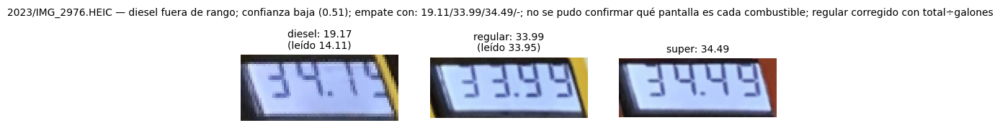

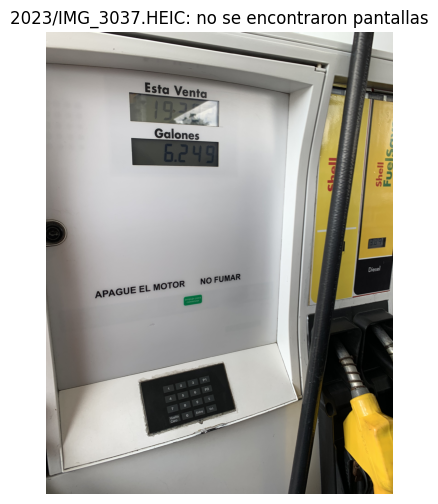

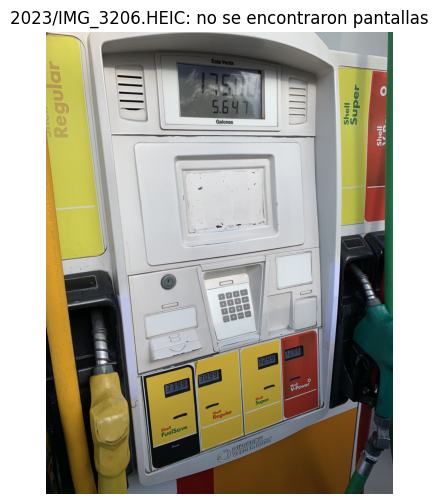

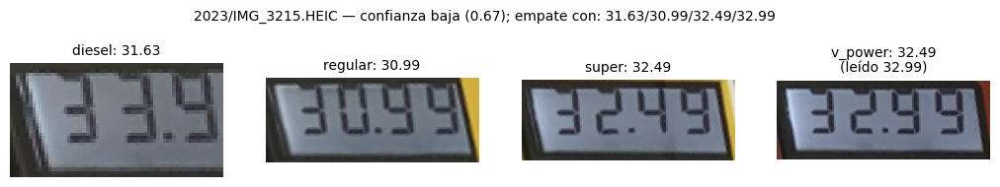

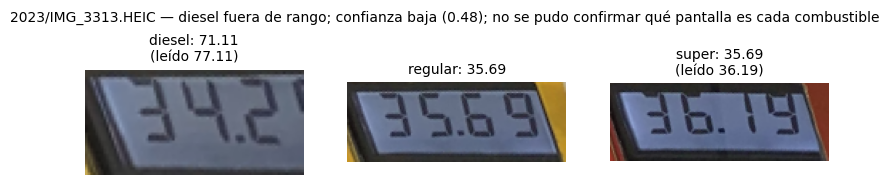

...

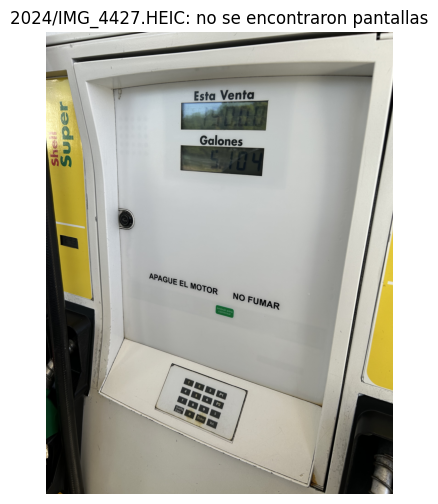

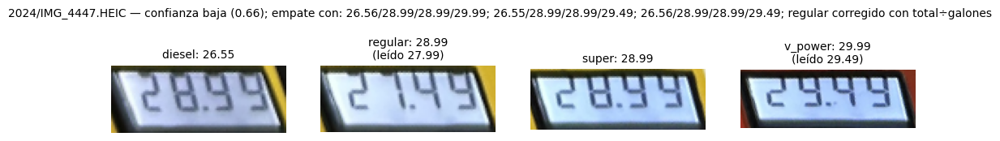

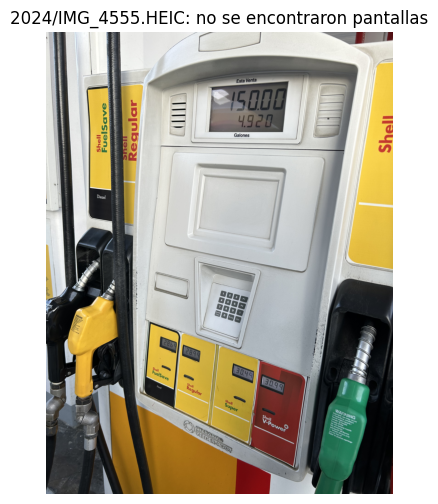

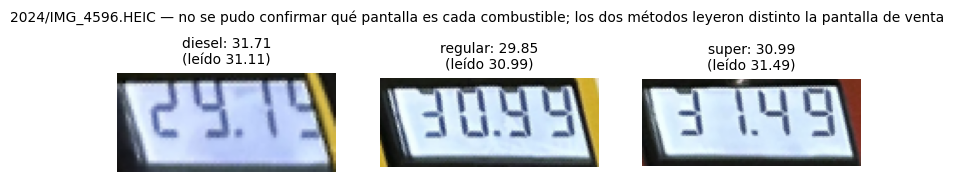

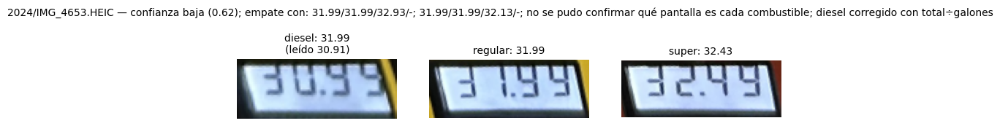




To set the max cell output size, run:
   %set_cell_max_output_size_in_mb <size_in_mb>

Set size_in_mb to a value between 1 and 20
  


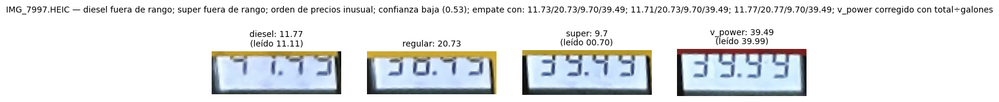

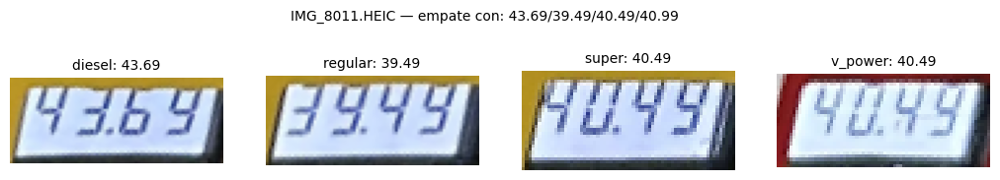

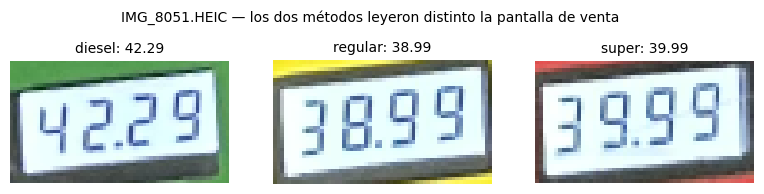

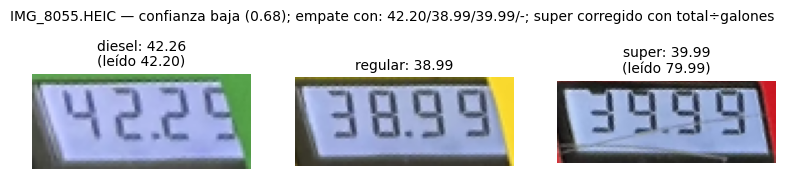

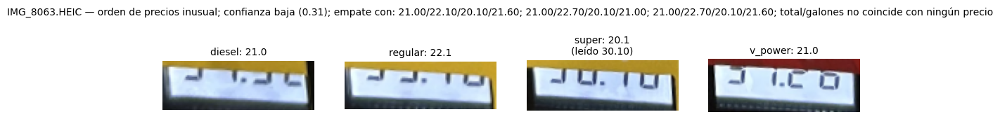

...

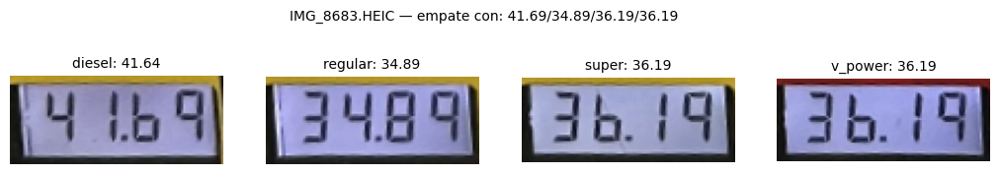

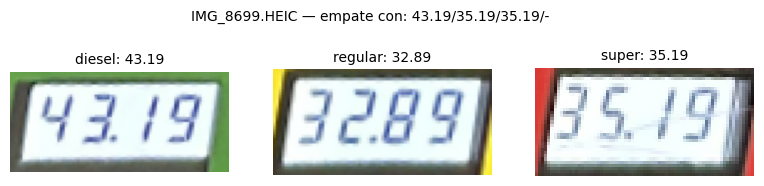

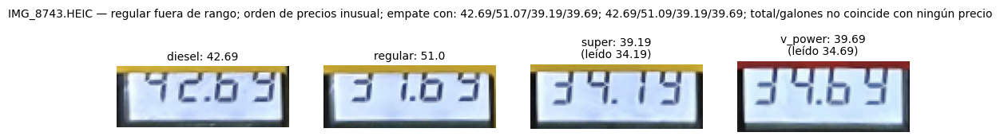

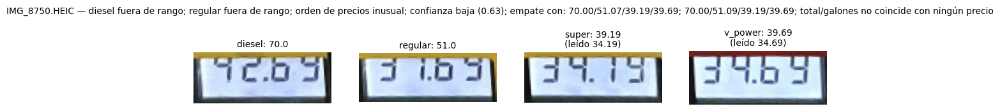

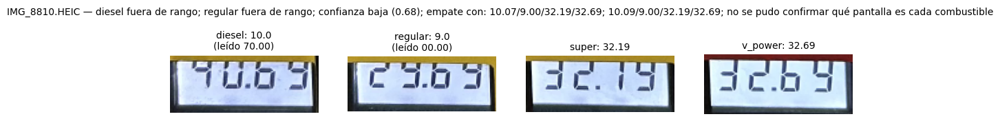

In [0]:
def revisar_foto(nombre):
    r = detalles.get(nombre)
    if r is None:
        print(f"{nombre}: sin detalles"); return
    img, cajas = r["_imagen"], r["_cajas"]
    if not cajas:
        plt.figure(figsize=(5, 6)); plt.imshow(img[..., ::-1]); plt.axis("off")
        plt.title(f"{nombre}: no se encontraron pantallas"); plt.show(); return
    fig, axs = plt.subplots(1, len(cajas), figsize=(3.2 * len(cajas), 1.8))
    axs = np.atleast_1d(axs)
    fila = df[df["archivo"] == nombre].iloc[0]
    for ax, caja, comb in zip(axs, cajas, r.get("_asignacion", COMBUSTIBLES)):
        ax.imshow(recortar(img, caja)[..., ::-1]); ax.axis("off")
        crudo = r.get(comb + "_crudo")
        ax.set_title(f"{comb}: {fila[comb]}" + (f"\n(leído {crudo})" if crudo and _num(crudo) != fila[comb] else ""),
                     fontsize=10)
    fig.suptitle(f"{nombre} — {fila['alertas'] or 'sin alertas'}", fontsize=10, y=1.12)
    plt.show()

marcadas = df.loc[df["revisar"], "archivo"].tolist()
print(f"{len(marcadas)} de {len(df)} foto(s) para revisar")
for n in marcadas:
    revisar_foto(n)

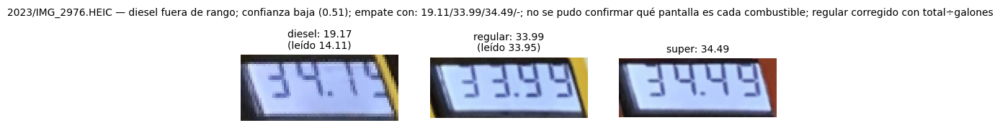

In [0]:
# Ver cualquier foto en detalle, por ejemplo la primera:
if len(df):
    revisar_foto(df["archivo"].iloc[0])

## 7. Resultados y exportación

In [0]:
ok = df[df[COMBUSTIBLES].notna().any(axis=1)]
print(f"Fotos: {len(df)}  |  con precios: {len(ok)}  |  para revisar: {int(df['revisar'].sum())}")
if len(ok):
    display(ok[COMBUSTIBLES].agg(["count", "mean", "min", "max"]).round(2))

exportar = df.drop(columns=[c for c in df.columns if c.endswith("_crudo") or c in ("costo_resolucion",)])

def a_spark(pdf):
    """pandas -> Spark con tipos explícitos (evita errores con columnas vacías o tipos de NumPy)."""
    from pyspark.sql import types as T
    campos, conv = [], {}
    for c in pdf.columns:
        dt = pdf[c].dtype
        if c == "fecha":
            tipo, f = T.DateType(), (lambda v: pd.Timestamp(v).date())
        elif pd.api.types.is_bool_dtype(dt):
            tipo, f = T.BooleanType(), bool
        elif pd.api.types.is_integer_dtype(dt):
            tipo, f = T.LongType(), int
        elif pd.api.types.is_float_dtype(dt):
            tipo, f = T.DoubleType(), float
        elif pd.api.types.is_datetime64_any_dtype(dt):
            tipo, f = T.TimestampType(), (lambda v: pd.Timestamp(v).to_pydatetime())
        else:
            tipo, f = T.StringType(), str
        campos.append(T.StructField(c, tipo, True))
        conv[c] = f
    filas = [tuple(None if pd.isna(v) else conv[c](v) for c, v in zip(pdf.columns, fila))
             for fila in pdf.itertuples(index=False, name=None)]
    return spark.createDataFrame(filas, schema=T.StructType(campos))

if EN_DATABRICKS:
    ahora = pd.Timestamp.now()

    # ---- BRONZE: lectura cruda de cada foto (EXIF + precios tal como salieron del lector) ----
    lecturas_raw = df_meta.merge(df_precios, on="archivo", how="left")
    lecturas_raw["procesado_en"] = ahora
    spark.sql(f"DROP TABLE IF EXISTS {T_BRONZE_LECT}")      # la versión vieja estaba en el catálogo, no en S3
    (a_spark(lecturas_raw).write.mode("overwrite").option("overwriteSchema", "true")
        .option("path", f"{RUTA_BRONZE}lecturas_raw").saveAsTable(T_BRONZE_LECT))
    print(f"Bronze: {T_BRONZE_LECT}  ({len(lecturas_raw)} filas)")
    display(spark.table(T_BRONZE_LECT))

else:
    exportar.to_csv(SALIDA_CSV, index=False, encoding="utf-8-sig")
    with pd.ExcelWriter(SALIDA_XLSX) as xw:
        exportar.to_excel(xw, sheet_name="precios", index=False)
        if len(ok):
            ok.groupby("fecha")[COMBUSTIBLES].mean().round(2).to_excel(xw, sheet_name="por_dia")
    print(f"Guardado: {SALIDA_CSV}\n          {SALIDA_XLSX}")


Fotos: 110  |  con precios: 87  |  para revisar: 100


diesel,regular,super,v_power
81.0,86.0,83.0,66.0
31.69,29.69,32.51,33.21
0.01,0.15,0.7,0.7
73.03,71.33,57.07,62.0


Bronze: equipo4.bronze.lecturas_raw  (110 filas)


archivo,carpeta,fecha_hora,fecha_origen,dispositivo,latitud,longitud,altitud_m,alternativas,confianza,confirmado_por_venta,corregido_por_venta,costo_resolucion,diesel,diesel_crudo,orden,pantallas_encontradas,precio_implicito,regular,regular_crudo,rotacion,super,super_crudo,v_power,v_power_crudo,venta_estado,venta_galones,venta_ocr,venta_propio,venta_total_q,procesado_en
2023/IMG_2976.HEIC,2023,2022-12-14T20:45:40.000Z,exif,Apple iPhone XS,14.560064,-90.462792,1862.9,19.11/33.99/34.49/-,0.51,null,regular,17.362,19.17,14.11,sin_confirmar,3,33.99,33.99,33.95,24.1,34.49,34.49,null,null,propio,5.884,null,200.0/5.884,200.0,2026-11-18T00:39:21.780Z
2023/IMG_3037.HEIC,2023,2022-12-30T13:32:26.000Z,exif,Apple iPhone XS,14.549444,-90.454436,1897.1,null,0.0,null,null,null,null,null,sin_pantallas,0,null,null,null,0.0,null,null,null,null,ninguno,null,null,null,null,2026-11-18T00:39:21.780Z
2023/IMG_3206.HEIC,2023,2023-01-01T15:32:28.000Z,exif,Apple iPhone XS,14.560114,-90.462775,1864.0,null,0.0,null,null,null,null,null,sin_pantallas,0,null,null,null,0.0,null,null,null,null,ninguno,null,null,null,null,2026-11-18T00:39:21.780Z
2023/IMG_3215.HEIC,2023,2023-01-02T13:43:31.000Z,exif,Apple iPhone XS,14.560117,-90.462753,1863.8,31.63/30.99/32.49/32.99,0.67,super,null,8.56,31.63,31.63,shell_normal,4,32.49,30.99,30.99,16.7,32.49,32.49,32.49,32.99,ocr,6.156,200.0/6.156,null,200.0,2026-11-18T00:39:21.780Z
2023/IMG_3247.HEIC,2023,2023-01-13T20:03:47.000Z,exif,Apple iPhone XS,14.588497,-90.507378,1509.7,,0.72,null,null,7.18,35.99,35.99,shell_normal,4,null,32.59,52.59,20.3,33.99,33.99,34.49,34.49,ninguno,null,null,null,null,2026-11-18T00:39:21.780Z
2023/IMG_3313.HEIC,2023,2023-01-30T12:49:41.000Z,exif,Apple iPhone XS,14.58375,-90.486106,1566.7,,0.48,regular,null,21.522,71.11,77.11,sin_confirmar,3,35.69,35.69,35.69,20.0,35.69,36.19,null,null,ocr,5.604,200.0/5.604,null,200.0,2026-11-18T00:39:21.780Z
2023/IMG_3333.HEIC,2023,2023-02-09T22:02:00.000Z,exif,Apple iPhone XS,14.560464,-90.462556,1866.5,34.97/34.69/35.19/-; 39.91/34.69/35.19/-; 39.97/34.69/35.19/-,0.66,null,null,12.08,34.91,34.91,sin_confirmar,3,null,34.69,34.69,23.7,35.19,35.19,null,null,ninguno,null,null,null,null,2026-11-18T00:39:21.780Z
2023/IMG_3362.HEIC,2023,2023-02-26T16:33:36.000Z,exif,Apple iPhone XS,14.549547,-90.4544,1907.0,null,0.0,null,null,null,null,null,sin_pantallas,0,33.19,null,null,0.0,null,null,null,null,ocr,7.532,250.0/7.532,null,250.0,2026-11-18T00:39:21.780Z
2023/IMG_3388.HEIC,2023,2023-03-15T20:52:25.000Z,exif,Apple iPhone XS,14.560231,-90.462586,1868.1,30.93/33.79/34.29/-; 30.95/33.79/34.29/-,0.75,regular,null,9.9,30.91,30.91,sin_confirmar,3,33.79,33.79,33.79,12.1,34.29,34.29,null,null,propio,5.919,null,200.0/5.919,200.0,2026-11-18T00:39:21.780Z
2023/IMG_3402.HEIC,2023,2023-03-20T20:13:31.000Z,exif,Apple iPhone XS,14.560281,-90.462683,1863.3,,0.78,super,null,4.935,30.55,30.55,shell_normal,4,32.99,31.35,31.35,10.0,32.99,32.99,33.49,33.49,ambos,4.547,150.0/4.547,150.0/4.547,150.0,2026-11-18T00:39:21.780Z


In [0]:
display(dbutils.fs.ls(RUTA_BRONZE))

path,name,size,modificationTime
s3://cc3105-cusn-869227452861-us-east-2-an/equipo4/fotos_precios/,fotos_precios/,0,0
s3://cc3105-cusn-869227452861-us-east-2-an/equipo4/lecturas_raw/,lecturas_raw/,0,0


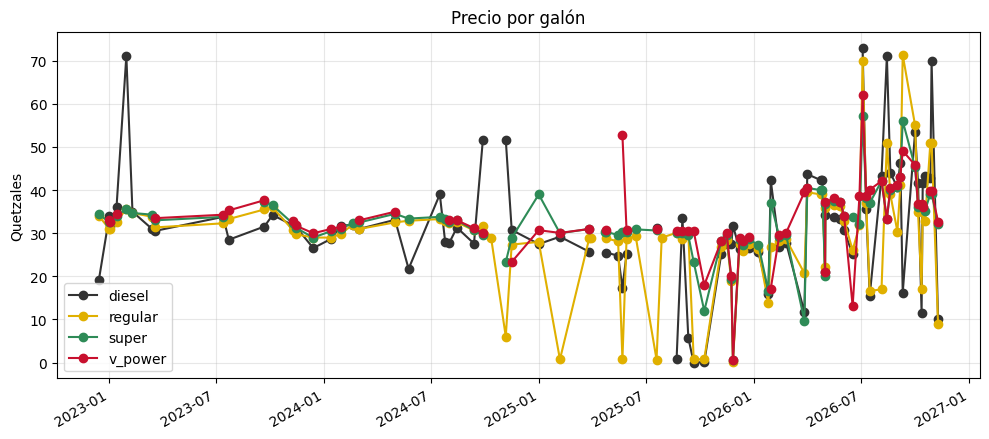

In [0]:
# Evolución de precios
serie = ok.dropna(subset=["fecha_hora"]).set_index("fecha_hora")[COMBUSTIBLES].dropna(axis=1, how="all")
if len(serie):
    colores = {"diesel": "#333333", "regular": "#E0B000", "super": "#2E8B57", "v_power": "#C8102E"}
    ax = serie.plot(marker="o", figsize=(10, 4.5), color=[colores[c] for c in serie.columns])
    ax.set_title("Precio por galón"); ax.set_ylabel("Quetzales"); ax.set_xlabel("")
    ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()